In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# repo root: works whether the notebook is opened from notebooks/ or from the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))     # lets us import the sandwich package even without pip install

from sandwich.config import load_problem
from sandwich.optimisation.problem import SandwichProblem
from sandwich.optimisation.run import load_moga_config, load_surrogate

cfg = load_moga_config()            # algorithm settings from config/moga.yaml
surrogate = load_surrogate(cfg)     # trained ANN + Eq. 16 scalers, loaded once
problem = SandwichProblem(surrogate)    # design space and limits, read from design_space.yaml once

# every number below comes from the YAML files, nothing is typed in twice
print("t_c bounds (Table 4):     ", (problem.xl[0], problem.xu[0]), "mm")
print("core densities (Table 2): ", problem.densities)
print("material codes (Table 4): ", problem.codes)
print("fixed load:               ", problem.p, "MPa")
print(f"limits (Eqs. 22-27):       SF >= {problem.sf_min}, C_delta <= 1.0, t_sw <= {problem.t_max} mm")
print("algorithm:                ", {k: cfg["algorithm"][k] for k in ("name", "n_evaluations", "pop_size", "seed")})

t_c bounds (Table 4):      (np.float64(5.0), np.float64(20.0)) mm
core densities (Table 2):  [29. 37. 42. 54. 59. 83.]
material codes (Table 4):  [1 2 3]
fixed load:                0.004142 MPa
limits (Eqs. 22-27):       SF >= 1.0, C_delta <= 1.0, t_sw <= 20.0 mm
algorithm:                 {'name': 'NSGA2', 'n_evaluations': 23000, 'pop_size': 100, 'seed': 1}


In [2]:
from sandwich.sampling import INPUT_COLS, OUTPUT_COLS

print("lower bounds:", problem.xl)
print("upper bounds:", problem.xu)

# Table 5 row 6: t_c 17.93 mm, 29 kg/m3 (index 0), layup 3,1,1,2,1,2 (indices 2,0,0,1,0,1)
x_knee = np.array([[17.93, 0, 2, 0, 0, 1, 0, 1]])
print("decoded:", dict(zip(INPUT_COLS, problem.decode(x_knee)[0])))

# ANN prediction vs exact solver for that design
pd.DataFrame({"ANN": surrogate.predict(problem.decode(x_knee))[0],
              "exact": problem.analytical(x_knee).iloc[0].to_numpy()},
             index=OUTPUT_COLS).T.style.format("{:.4g}")

lower bounds: [ 5.  -0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5]
upper bounds: [20.   5.5  2.5  2.5  2.5  2.5  2.5  2.5]
decoded: {'rho_c': np.float64(29.0), 't_c': np.float64(17.93), 'L1': np.float64(3.0), 'L2': np.float64(1.0), 'L3': np.float64(1.0), 'L4': np.float64(2.0), 'L5': np.float64(1.0), 'L6': np.float64(2.0), 'p': np.float64(0.004142)}


,SF_c,SF_f,SF_int,SF_wr,C_delta,t_sw,C_t,W_t
ANN,4.522,11.11,68.68,21.74,1.012,19.58,2.154,2.432
exact,4.528,11.09,69.25,21.75,1.015,19.58,2.154,2.433


In [3]:
from sandwich.optimisation.run import run_moga, save_result

result = run_moga(cfg, surrogate=surrogate)
m = result.metrics
for k in ("n_evaluations", "n_generations", "run_seconds", "cardinality", "distinct_designs", "spread_delta",
          "violation_rate", "hypervolume", "knee_W_t", "knee_C_t", "knee_design"):
    print(f"{k:<16} {m[k]}")

n_evaluations    23000
n_generations    231
run_seconds      10.23
cardinality      36
distinct_designs 15
spread_delta     1.1979395471894314
violation_rate   0.49786956521739134
hypervolume      2.1265587223149636
knee_W_t         2.4351284546740555
knee_C_t         2.1555556751931397
knee_design      {'rho_c': 29, 't_c': 18.081066824411025, 'layup': '1,2,1,3,1,2'}


In [4]:
cols = ["rho_c", "t_c", "layup", "W_t_ann", "C_t_ann", "W_t_exact", "C_t_exact",
        "C_delta_ann", "C_delta_exact", "feasible_exact", "D_imdsm", "knee"]
result.pareto[cols].style.format({"t_c": "{:.2f}", "W_t_ann": "{:.3f}", "C_t_ann": "{:.3f}",
                                  "W_t_exact": "{:.3f}", "C_t_exact": "{:.3f}", "C_delta_ann": "{:.4f}",
                                  "C_delta_exact": "{:.4f}", "D_imdsm": "{:.4f}"})

,rho_c,t_c,layup,W_t_ann,C_t_ann,W_t_exact,C_t_exact,C_delta_ann,C_delta_exact,feasible_exact,D_imdsm,knee
0,29,15.88,"1,1,1,1,1,1",1.857,2.495,1.865,2.497,0.9906,1.0000,True,0.6595,False
1,29,16.80,"1,2,1,1,1,1",1.915,2.408,1.915,2.408,0.9922,0.9999,True,0.6022,False
2,29,17.90,"1,2,1,1,1,2",1.970,2.321,1.968,2.320,0.9965,1.0000,True,0.5469,False
3,29,16.93,"1,1,1,3,1,2",2.381,2.243,2.381,2.242,0.9906,1.0000,True,0.5671,False
4,29,16.93,"1,2,1,1,3,1",2.381,2.243,2.381,2.242,0.9943,1.0000,True,0.5670,False
5,29,16.93,"1,2,1,1,1,3",2.381,2.243,2.381,2.242,0.9946,1.0000,True,0.5670,False
6,29,18.08,"1,2,1,3,1,2",2.435,2.156,2.436,2.156,0.9973,1.0000,True,0.5340,True
7,29,18.08,"1,2,1,1,3,2",2.435,2.155,2.436,2.156,0.9990,1.0000,True,0.5340,False
8,29,18.08,"3,2,1,1,1,2",2.436,2.155,2.436,2.156,1.0005,1.0000,True,0.5341,False
9,29,17.08,"1,1,3,3,1,2",2.848,2.078,2.848,2.077,0.9934,1.0000,True,0.6563,False


baseline (ann constraints): 19 points, 2 of 19 truly feasible, knee W 2.435 kg, C 2.155


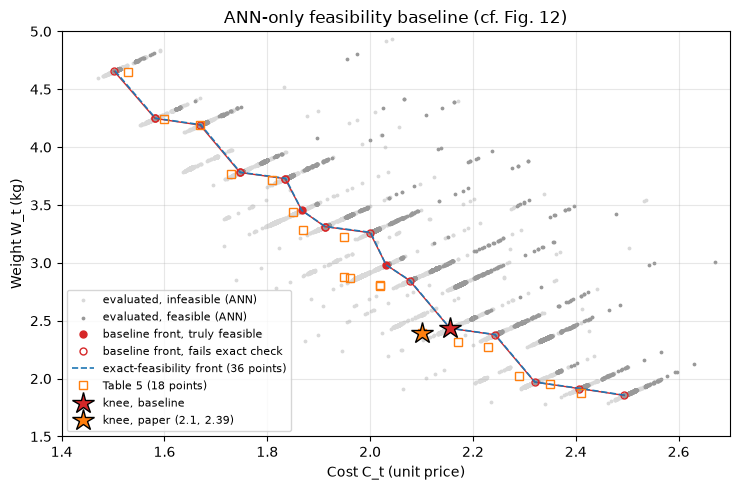

,rho_c,t_c,layup,W_t_ann,C_t_ann,W_t_exact,C_t_exact,C_delta_ann,C_delta_exact,feasible_exact,D_imdsm,knee
0,29,15.80,"1,1,1,1,1,1",1.855,2.494,1.863,2.496,1.0000,1.0095,False,0.6606,False
1,29,16.70,"1,1,1,1,1,2",1.914,2.407,1.913,2.407,0.9999,1.0096,False,0.6034,False
2,29,17.86,"1,2,1,1,1,2",1.970,2.320,1.967,2.320,1.0000,1.0035,False,0.5483,False
3,29,16.86,"1,2,1,3,1,1",2.379,2.242,2.380,2.242,0.9999,1.0078,False,0.5682,False
4,29,18.05,"1,2,1,3,1,2",2.435,2.155,2.435,2.155,1.0000,1.0027,False,0.5355,True
5,29,17.01,"1,2,1,3,1,3",2.847,2.077,2.847,2.077,1.0000,1.0068,False,0.6574,False
6,37,17.67,"2,2,1,1,3,3",2.983,2.031,2.984,2.031,0.9997,0.9979,True,0.7030,False
7,29,16.08,"1,3,1,3,3,1",3.261,2.000,3.261,1.999,1.0000,1.0136,False,0.8271,False
8,29,17.16,"2,3,1,3,3,1",3.313,1.912,3.314,1.912,0.9999,1.0069,False,0.8321,False
9,29,17.16,"1,2,1,3,3,3",3.313,1.912,3.314,1.912,0.9994,1.0066,False,0.8322,False


In [9]:
from sandwich.config import load_problem
from sandwich.optimisation.run import run_moga, save_result

# paper-style baseline: feasibility judged from the ANN's predicted constraints, no exact filter
baseline_cfg = load_moga_config(overrides={"feasibility": {"constraints_from": "ann",
                                                           "report_only_feasible": False}})
baseline = run_moga(baseline_cfg, surrogate=surrogate)          # same seed, so the same front as before
base_dir = save_result(baseline, "results/moga/ann_baseline")   # kept separately from the default run

# one-line summary so the two runs can be compared at a glance
mb = baseline.metrics
print(f"baseline ({mb['constraints_from']} constraints): {mb['cardinality']} points, "
      f"{mb['front_feasible_exact']} of {len(baseline.pareto)} truly feasible, "
      f"knee W {mb['knee_W_t']:.3f} kg, C {mb['knee_C_t']:.3f}")

# Pareto front plot, same axes as cell 9 (cf. Fig. 12)
paper = pd.DataFrame(load_problem()["pareto_designs"]["rows"])
knee_row = paper[paper.n == cfg["targets"]["knee_row"]].iloc[0]
arch, B = baseline.archive, baseline.pareto
ok = B.feasible_exact                                           # truly feasible by the exact solver

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(arch.C_t[~arch.feasible], arch.W_t[~arch.feasible], s=3, c="0.85", label="evaluated, infeasible (ANN)")
ax.scatter(arch.C_t[arch.feasible], arch.W_t[arch.feasible], s=3, c="0.6", label="evaluated, feasible (ANN)")
ax.plot(B.C_t_ann, B.W_t_ann, "-", color="tab:red", lw=1)
ax.plot(B.C_t_ann[ok], B.W_t_ann[ok], "o", ms=5, color="tab:red", label="baseline front, truly feasible")
ax.plot(B.C_t_ann[~ok], B.W_t_ann[~ok], "o", ms=5, mfc="none", color="tab:red", label="baseline front, fails exact check")
if "result" in globals():                                       # exact-feasibility front from cell 5, if it has run
    ax.plot(result.pareto.C_t_ann, result.pareto.W_t_ann, "--", color="tab:blue", lw=1.2,
            label=f"exact-feasibility front ({result.metrics['cardinality']} points)")
ax.plot(paper.Ct, paper.Wt, "s", ms=6, mfc="none", color="tab:orange", label="Table 5 (18 points)")
ax.plot(mb["knee_C_t"], mb["knee_W_t"], "*", ms=16, color="tab:red", mec="k", label="knee, baseline")
ax.plot(knee_row.Ct, knee_row.Wt, "*", ms=16, color="tab:orange", mec="k", label="knee, paper (2.1, 2.39)")
ax.set(xlim=(1.4, 2.7), ylim=(1.5, 5.0), xlabel="Cost C_t (unit price)", ylabel="Weight W_t (kg)",
       title="ANN-only feasibility baseline (cf. Fig. 12)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(base_dir / "front.png", dpi=150)                    # results/moga/ann_baseline/front.png
plt.show()

# same columns and number formats as the cell 7 table
cols = ["rho_c", "t_c", "layup", "W_t_ann", "C_t_ann", "W_t_exact", "C_t_exact",
        "C_delta_ann", "C_delta_exact", "feasible_exact", "D_imdsm", "knee"]
baseline.pareto[cols].style.format({"t_c": "{:.2f}", "W_t_ann": "{:.3f}", "C_t_ann": "{:.3f}",
                                    "W_t_exact": "{:.3f}", "C_t_exact": "{:.3f}", "C_delta_ann": "{:.4f}",
                                    "C_delta_exact": "{:.4f}", "D_imdsm": "{:.4f}"})

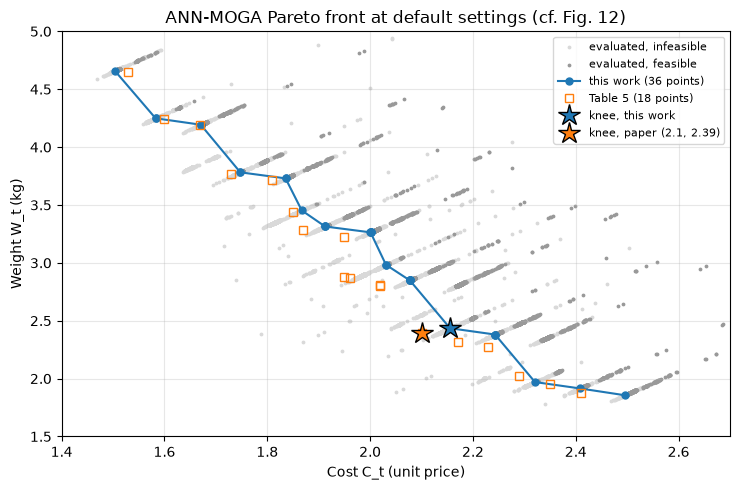

In [5]:
out_dir = ROOT / cfg["output_dir"]
out_dir.mkdir(parents=True, exist_ok=True)

paper = pd.DataFrame(load_problem()["pareto_designs"]["rows"])
knee_row = paper[paper.n == cfg["targets"]["knee_row"]].iloc[0]
arch, P = result.archive, result.pareto

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(arch.C_t[~arch.feasible], arch.W_t[~arch.feasible], s=3, c="0.85", label="evaluated, infeasible")
ax.scatter(arch.C_t[arch.feasible], arch.W_t[arch.feasible], s=3, c="0.6", label="evaluated, feasible")
ax.plot(P.C_t_ann, P.W_t_ann, "o-", ms=5, color="tab:blue", label=f"this work ({m['cardinality']} points)")
ax.plot(paper.Ct, paper.Wt, "s", ms=6, mfc="none", color="tab:orange", label="Table 5 (18 points)")
ax.plot(m["knee_C_t"], m["knee_W_t"], "*", ms=16, color="tab:blue", mec="k", label="knee, this work")
ax.plot(knee_row.Ct, knee_row.Wt, "*", ms=16, color="tab:orange", mec="k", label="knee, paper (2.1, 2.39)")
ax.set(xlim=(1.4, 2.7), ylim=(1.5, 5.0), xlabel="Cost C_t (unit price)", ylabel="Weight W_t (kg)",
       title="ANN-MOGA Pareto front at default settings (cf. Fig. 12)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(out_dir / "front.png", dpi=150)
plt.show()

In [10]:
from sandwich.optimisation.run import run_moga, save_result

# baseline (ANN-only feasibility): reuse it if the baseline cell already ran, otherwise run it now
if "baseline" not in globals():
    baseline_cfg = load_moga_config(overrides={"feasibility": {"constraints_from": "ann",
                                                               "report_only_feasible": False}})
    baseline = run_moga(baseline_cfg, surrogate=surrogate)


# Week 7 record for one run, as a column of the comparison table
def week7_record(r):
    m, P = r.metrics, r.pareto
    return pd.Series({
        "feasibility judged by": m["constraints_from"],
        "front size (paper 18)": m["cardinality"],
        "physically distinct designs (paper 16)": m["distinct_designs"],
        "spread, Deb delta": round(m["spread_delta"], 3),
        "violation rate, all evaluated": f"{m['violation_rate']:.1%}",
        "evaluations / generations": f"{m['n_evaluations']} / {m['n_generations']}",
        "knee W_t kg (paper 2.39)": round(m["knee_W_t"], 3),
        "knee C_t (paper 2.1)": round(m["knee_C_t"], 3),
        "knee design (density, t_c, layup)": f"{m['knee_design']['rho_c']}, "
                                             f"{m['knee_design']['t_c']:.2f}, {m['knee_design']['layup']}",
        "front feasible by exact solver": f"{m['front_feasible_exact']} of {len(P)}",
        "C_delta on front, ANN": f"{P.C_delta_ann.min():.4f} to {P.C_delta_ann.max():.4f}",
        "C_delta on front, exact (limit 1.0)": f"{P.C_delta_exact.min():.4f} to {P.C_delta_exact.max():.4f}",
        "max ANN error on front, W_t / C_t": f"{m['max_rel_err_W_t']:.2%} / {m['max_rel_err_C_t']:.2%}",
        "run time (s)": m["run_seconds"],
    })


# both runs side by side, one column each
comparison = pd.concat({"exact feasibility (default)": week7_record(result),
                        "ANN-only feasibility (paper)": week7_record(baseline)}, axis=1)
display(comparison)

# save both runs to their own folders
saved = save_result(result)                                      # results/moga/default
saved_base = save_result(baseline, "results/moga/ann_baseline")  # results/moga/ann_baseline
comparison.to_csv(ROOT / "results/moga/week7_comparison.csv")
print("saved to", saved.relative_to(ROOT), "and", saved_base.relative_to(ROOT))
print("comparison table saved to results/moga/week7_comparison.csv")

,exact feasibility (default),ANN-only feasibility (paper)
feasibility judged by,exact,ann
front size (paper 18),36,19
physically distinct designs (paper 16),15,15
"spread, Deb delta",1.198,0.493
"violation rate, all evaluated",49.8%,50.1%
evaluations / generations,23000 / 231,23000 / 231
knee W_t kg (paper 2.39),2.435,2.435
knee C_t (paper 2.1),2.156,2.155
"knee design (density, t_c, layup)","29, 18.08, 1,2,1,3,1,2","29, 18.05, 1,2,1,3,1,2"
front feasible by exact solver,36 of 36,2 of 19


saved to results/moga/default and results/moga/ann_baseline
comparison table saved to results/moga/week7_comparison.csv
